# CA3 LogReg

### Imports

In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from itertools import combinations


### Settings

In [66]:
LogReg_test_runs = 50 # How many logistic regression random states to test on all states are unique
C_test = False # Set True to test LogReg C parameter
use_random_forest_attributes = True # Use most important attributes according to random forest

### Reading data

In [67]:
df_wine = pd.read_csv(r"train.csv")
df_wine_test = pd.read_csv(r"test.csv")

### Data exploration and visualisation

In [68]:
# Check for nan values in columns
df_wine.isna().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64

In [69]:
# Check whether a column contains a negative value or not
(df_wine < 0).any()

fixed acidity           False
volatile acidity        False
citric acid             False
residual sugar          False
chlorides               False
free sulfur dioxide     False
total sulfur dioxide    False
density                 False
pH                      False
sulphates               False
alcohol                 False
quality                 False
Id                      False
dtype: bool

In [70]:
df_wine.info()

<class 'pandas.DataFrame'>
RangeIndex: 835 entries, 0 to 834
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         835 non-null    float64
 1   volatile acidity      835 non-null    float64
 2   citric acid           835 non-null    float64
 3   residual sugar        835 non-null    float64
 4   chlorides             835 non-null    float64
 5   free sulfur dioxide   835 non-null    float64
 6   total sulfur dioxide  835 non-null    float64
 7   density               835 non-null    float64
 8   pH                    835 non-null    float64
 9   sulphates             835 non-null    float64
 10  alcohol               835 non-null    float64
 11  quality               835 non-null    int64  
 12  Id                    835 non-null    int64  
dtypes: float64(11), int64(2)
memory usage: 84.9 KB


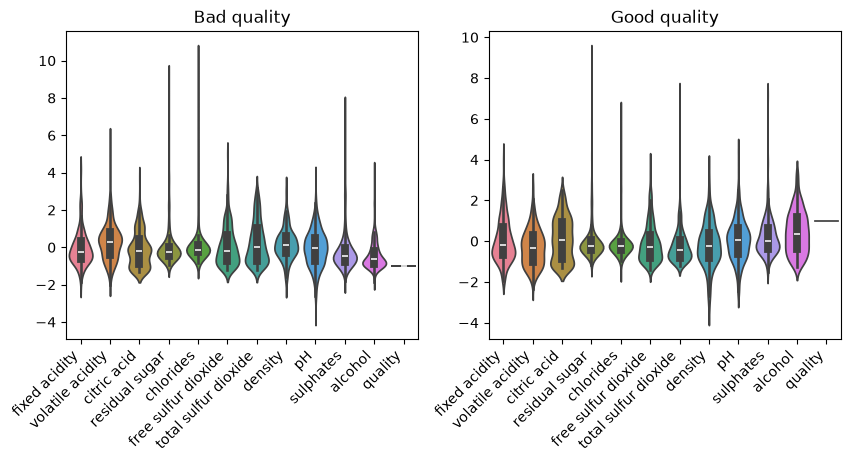

In [71]:
df_plot = df_wine.drop(columns=["Id"])

column_names = df_plot.columns

for name in column_names:
    df_plot[name] = (df_plot[name]-df_plot[name].mean())/df_plot[name].std()

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

plt.setp(ax[0].get_xticklabels(), rotation=45, ha='right')
plt.setp(ax[1].get_xticklabels(), rotation=45, ha='right')

ax[0].set_title("Bad quality")
ax[1].set_title("Good quality")

sns.violinplot(data=df_plot.loc[df_wine["quality"]==0], ax=ax[0])
sns.violinplot(data=df_plot.loc[df_wine["quality"]==1], ax=ax[1])

plt.show()

### Parameter comparison <br>
High negative differnce indicate a attribute that greatly push quality towards bad, and a high positive value indicates the attribute greatly pushes towards a good quality.



In [72]:
df_wine.loc[df_wine["quality"]==1].describe()-df_wine.loc[df_wine["quality"]==0].describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
count,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0,1.000000
mean,0.180333,-0.108611,0.043878,-0.058067,-0.010629,-1.554158,-16.643323,-0.000697,0.015764,0.078879,0.982286,1.0,103.191835
std,0.271887,-0.015871,0.022611,-0.157256,-0.017362,-1.020152,-10.108383,0.000491,0.003305,-0.011330,0.373532,0.0,-43.464688
min,0.300000,-0.060000,0.000000,-0.300000,-0.027000,-2.000000,0.000000,-0.002510,0.150000,0.060000,0.600000,1.0,8.000000
25%,-0.100000,-0.110000,0.010000,0.000000,-0.009000,-1.000000,-3.000000,-0.001035,0.020000,0.070000,0.600000,1.0,164.500000
50%,0.100000,-0.110000,0.050000,0.000000,-0.004000,-1.000000,-15.000000,-0.000645,0.020000,0.090000,1.100000,1.0,201.500000
75%,0.600000,-0.100000,0.100000,0.000000,-0.007250,-4.000000,-31.250000,-0.000393,0.020000,0.120000,1.500000,1.0,-21.500000
max,-0.300000,-0.540000,-0.240000,-0.100000,-0.196000,-13.000000,137.000000,0.000540,0.110000,-0.050000,-0.900000,1.0,-2.000000


Mean values close to zero are considered negligible, and the attribute which has is not considered when training.

From this we see that a high total sulfur dioxide content pushes the quality towards bad

|                      | trend | mean   | negligible |
|----------------------|-------|--------|------------|
| fixed acidity        | Good  | 0.18   | False      |
| volatile acidity     | Bad   | -0.10  | False      |
| citric acid          | Good  | 0.04   | True       |
| residual sugar       | Bad   | -0.05  | True       |
| chlorides            | Bad   | -0.01  | True       |
| free sulfur dioxide  | Bad   | -1.55  | False      |
| total sulfur dioxide | Bad   | -16.64 | False      |
| density              | Bad   | -0.00  | True       |
| pH                   | Good  | 0.02   | True       |
| sulphates            | Good  | 0.07   | True      |
| alcohol              | Good  | 0.98   | False      |

### Data cleaning

In [73]:
if use_random_forest_attributes == True:
    df_train = df_wine.drop(columns=["chlorides", "pH", "citric acid", "fixed acidity", "free sulfur dioxide", "residual sugar", "Id"])
    df_test = df_wine_test.drop(columns=["chlorides", "pH", "citric acid", "fixed acidity", "free sulfur dioxide", "residual sugar", "Id"])
else:
    df_train = df_wine.drop(columns=["citric acid", "residual sugar", "chlorides", "density", "pH", "sulphates", "Id"])
    df_test = df_wine_test.drop(columns=["citric acid", "residual sugar", "chlorides", "density", "pH", "sulphates", "Id"])

df_train

,volatile acidity,total sulfur dioxide,density,sulphates,alcohol,quality
0,0.610,29.0,0.99740,1.56,9.1,0
1,1.035,54.0,0.99900,0.49,9.9,0
2,0.290,53.0,0.99500,1.01,12.4,1
3,0.340,63.0,0.99160,0.79,14.0,1
4,0.645,23.0,1.00315,0.74,11.1,0
...,...,...,...,...,...,...
830,0.320,9.0,0.99506,0.55,12.3,1
831,0.510,54.0,0.99500,0.93,10.7,1
832,0.725,11.0,0.99620,0.39,10.9,0
833,0.835,19.0,0.99660,0.47,9.6,0


### Are attributes choosen linearly separable?

Most attributes are not linearly separable, but some show possibility of being linearly separable

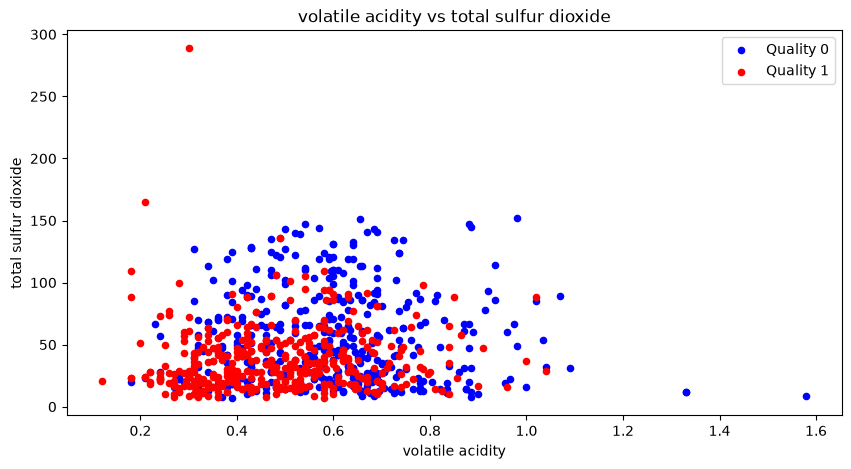

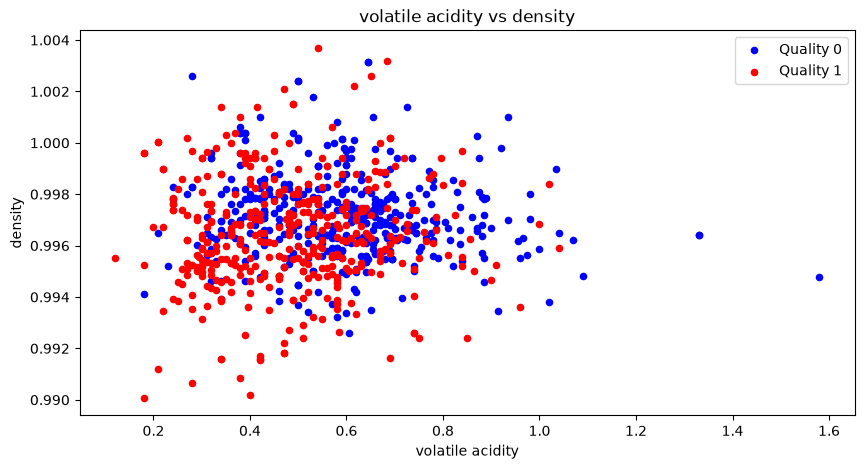

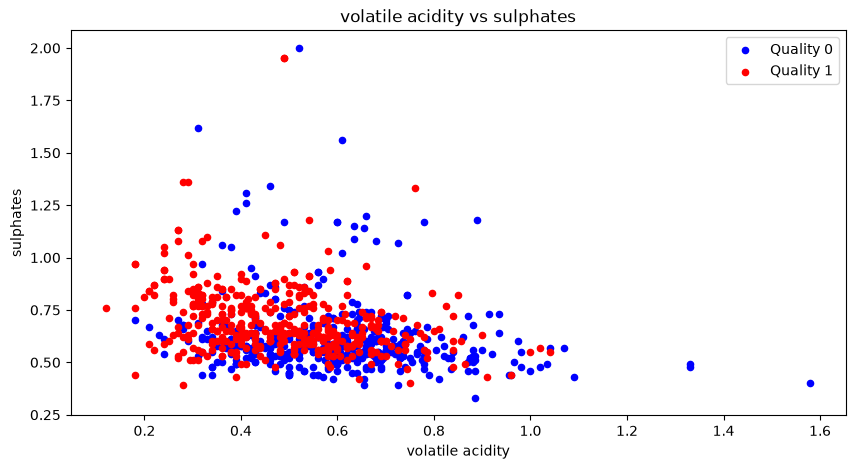

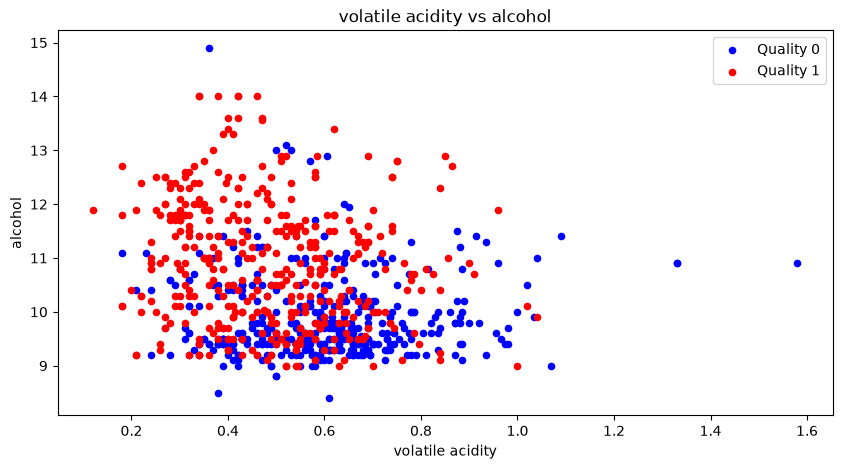

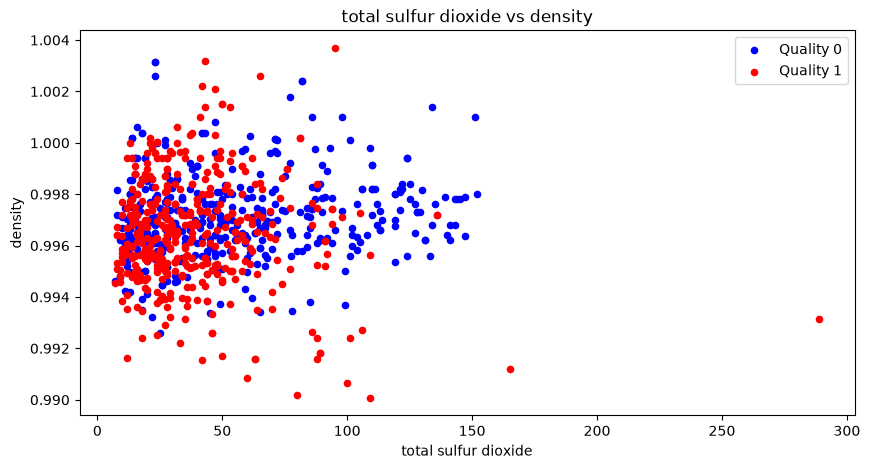

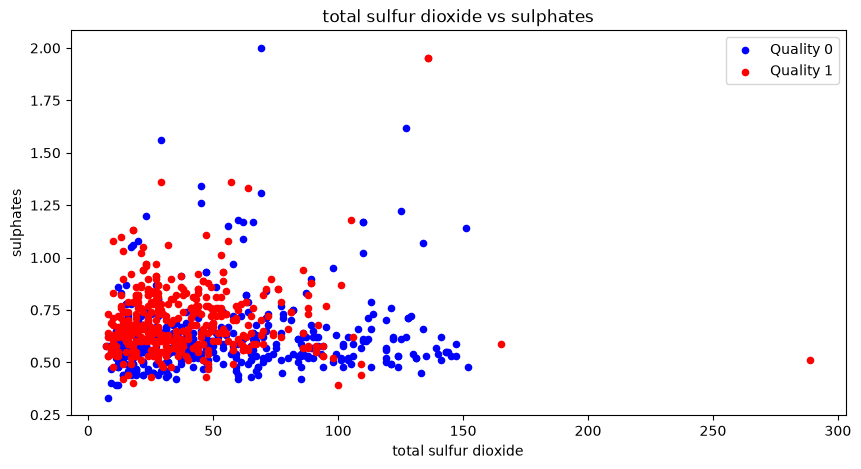

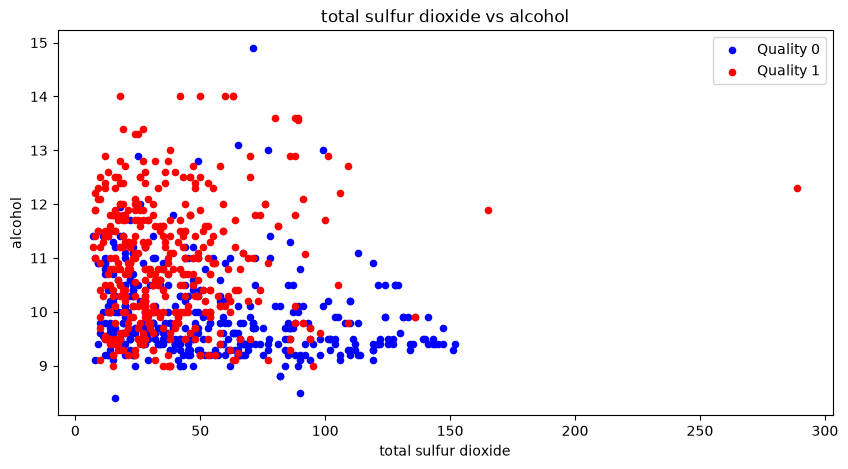

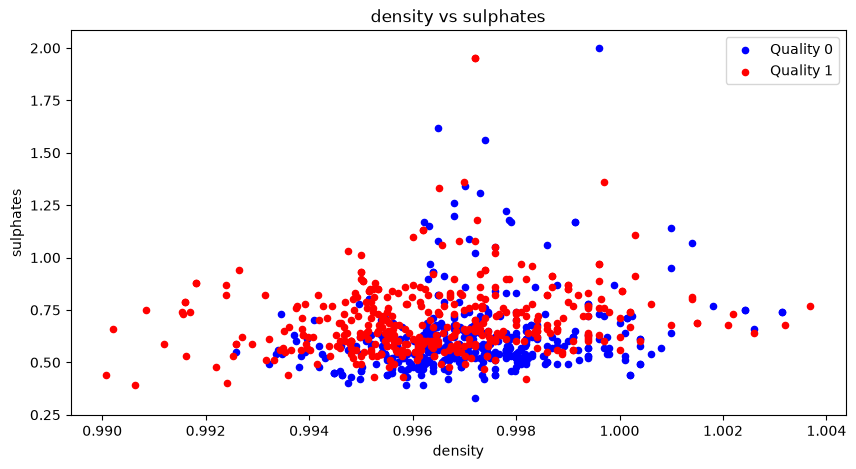

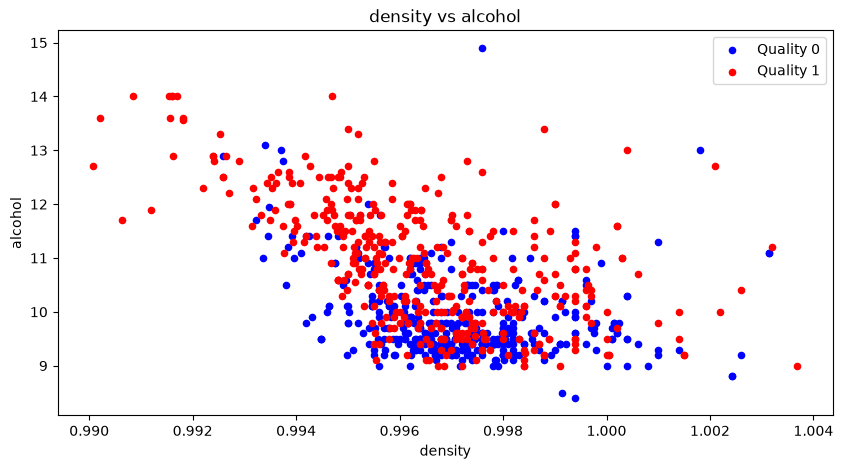

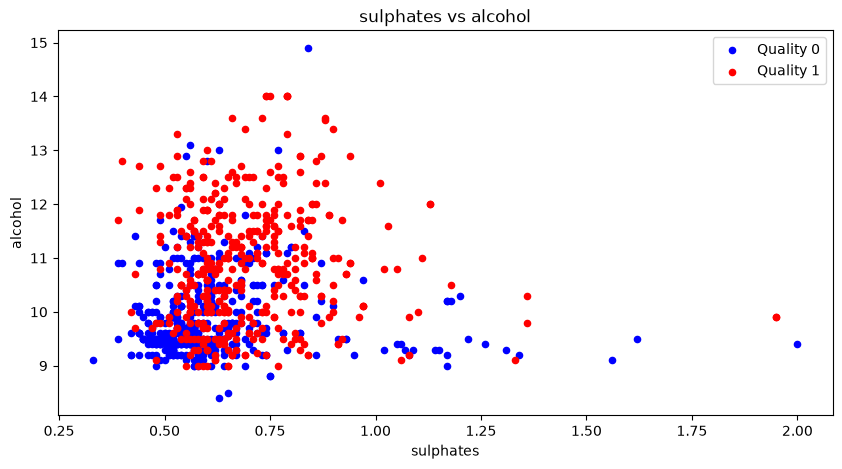

In [74]:
# Finds all combinations of features to plot except class
plot_combos = list(combinations(df_train.columns[:-1], 2))

for combo in plot_combos:
    fig, ax = plt.subplots(figsize=(10, 5))
    df_train.loc[df_train["quality"] == 0].plot.scatter(ax=ax, x=combo[0], y=combo[1], color="blue", label="Quality 0")
    df_train.loc[df_train["quality"] == 1].plot.scatter(ax=ax, x=combo[0], y=combo[1], color="red", label="Quality 1")
    ax.legend()
    ax.set_title(f"{combo[0]} vs {combo[1]}")
    plt.show()

### Data preprocessing and visualisation

In [75]:
# Separate into class labels and attributes
column_names = df_train.columns
df_y = df_train.drop(columns=[x for x in column_names if x != "quality"])
df_train = df_train.drop(columns="quality")


### Logistic regression trials

In [76]:
rng = np.random.default_rng()

print(f"Intializing logistic regression test run. Current amount of test runs {LogReg_test_runs}")
LogReg_run_data = np.zeros((LogReg_test_runs, 3))
scaler_train = StandardScaler()
C = np.linspace(0, 10, LogReg_test_runs+1)[1:]
best_score = 0
best_c = 0

# Based on settings run test LogReg models and parameters
random_states = rng.choice(1000, size=LogReg_test_runs, replace=False)
for idx, rand_num in enumerate(random_states):
    if C_test == True:
        for state in random_states:
            X_train, X_val, y_train, y_val = train_test_split(df_train, df_y, test_size=0.3, random_state=state, stratify=df_y)

            # Scale data, split data
            scaler_train.fit(X_train)
            X_train_scaled = pd.DataFrame(scaler_train.transform(X_train))
            X_val_scaled = pd.DataFrame(scaler_train.transform(X_val))

            # Train logistic regression model
            clf = LogisticRegression(C=C[idx]).fit(X_train_scaled, np.array(y_train).flatten())
            LogReg_score = clf.score(X_val_scaled, np.array(y_val).flatten())
            LogReg_run_data[idx, 0] = LogReg_score
            LogReg_run_data[idx, 1] = rand_num
            LogReg_run_data[idx, 2] = C[idx]

            avg_score = LogReg_run_data[:, 0].mean()
            if best_score < avg_score:
                best_score = avg_score
                best_c = LogReg_run_data[idx, 2]

    else:
        X_train, X_val, y_train, y_val = train_test_split(df_train, df_y, test_size=0.3, random_state=rand_num, stratify=df_y)
        # Scale data, split data
        scaler_train.fit(X_train)
        X_train_scaled = pd.DataFrame(scaler_train.transform(X_train))
        X_val_scaled = pd.DataFrame(scaler_train.transform(X_val))

        # Train logistic regression model
        clf = LogisticRegression().fit(X_train_scaled, np.array(y_train).flatten())
        LogReg_score = clf.score(X_val_scaled, np.array(y_val).flatten())
        LogReg_run_data[idx, 0] = LogReg_score
        LogReg_run_data[idx, 1] = rand_num
        LogReg_run_data[idx, 2] = 1


LogReg_run_data[:, 0] = LogReg_run_data[:, 0]*100

# Find highest and lowest data points
LogReg_max_index = np.argmax(LogReg_run_data[:, 0])
LogReg_min_index = np.argmin(LogReg_run_data[:, 0])

print(f"""
Average score {LogReg_run_data[:, 0].mean():.2f}
std of score {LogReg_run_data[:, 0].std():.2f}
Max score {LogReg_run_data[LogReg_max_index, 0]:.2f}, random state {LogReg_run_data[LogReg_max_index, 1]:.0f}, C {C[LogReg_max_index]}
Min score {LogReg_run_data[LogReg_min_index, 0]:.2f}, random state {LogReg_run_data[LogReg_min_index, 1]:.0f}, C {C[LogReg_min_index]}
""")

if C_test == True:
    print(f"""
Best C {best_c}
Best Score {best_score}
""")

# Scale training data then use same scale to transform test data
scaler_train.fit(df_train)
df_train_scaled = pd.DataFrame(scaler_train.transform(df_train))
df_test_scaled = pd.DataFrame(scaler_train.transform(df_test))

# Used scaled training data to train LogReg model
clf = LogisticRegression(C=1).fit(df_train_scaled, np.array(df_y).flatten())

# Finds
"""
Best C found: 1.0
Default C performed best in range 0-1

Best C found is always the largest number. High risk of overfitting when high
"""



Intializing logistic regression test run. Current amount of test runs 50

Average score 74.53
std of score 2.35
Max score 79.68, random state 303, C 5.4
Min score 69.72, random state 553, C 1.8



'\nBest C found: 1.0\nDefault C performed best in range 0-1\n\nBest C found is always the largest number. High risk of overfitting when high\n'

### Kaggle export data

In [77]:
# Predict using scaled test set
submission = pd.DataFrame(clf.predict(df_test_scaled), columns=["TARGET"])
submission.index.name = "Id"
submission.to_csv("Kaggle_LogReg_result.csv")